In [1]:

# Install the RDKit library using pip
!pip install rdkit==2026.3.1

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.0/37.0 MB 51.4 MB/s eta 0:00:00


In [2]:
#To confirm the installation, let's import the library and check its version.
import rdkit
print(rdkit.__version__)

2026.03.1


In [3]:
from rdkit import Chem
from rdkit.Chem import Draw

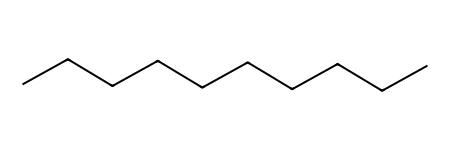

In [4]:
#structure of decane
from rdkit import Chem
decane = Chem.MolFromSmiles("CCCCCCCCCC")
decane

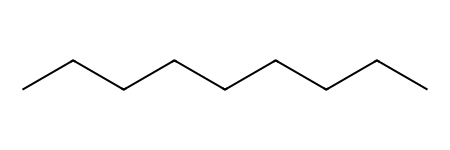

In [5]:
#structure of nonane
from rdkit import Chem
nonane = Chem.MolFromSmiles("CCCCCCCCC")
nonane

In [6]:
#Downolad Structure
from rdkit import Chem

octane = Chem.MolFromSmiles("CCCCCCCC")

Chem.MolToMolFile(octane, "octane.sdf")
Chem.MolToMolFile(octane, "octane.mol")

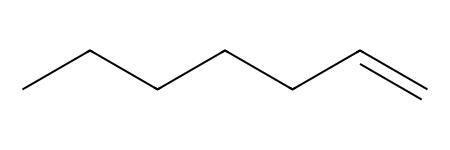

In [7]:
#heptene
heptene = Chem.MolFromSmiles("CCCCCC=C")
heptene

In [ ]:
# 2,2-dimethylpropane (neopentane)
mol2 = Chem.MolFromSmiles("CC(C)(C)C")
mol2

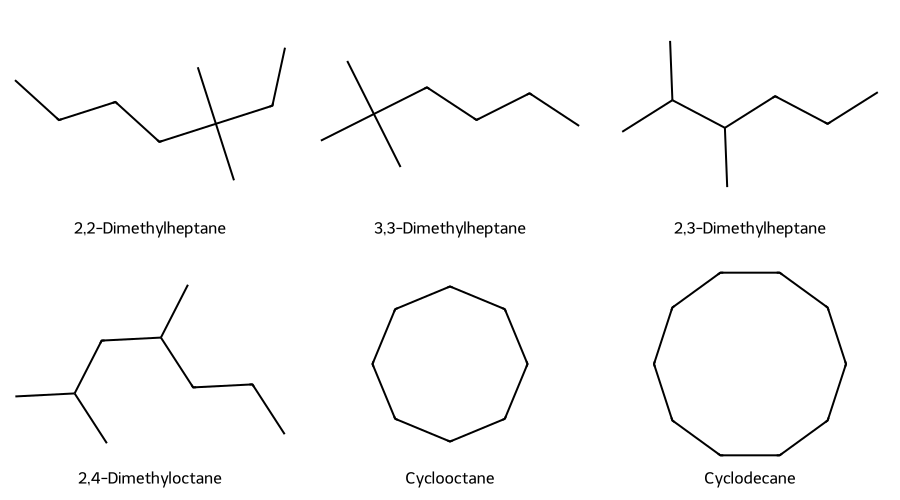

In [1]:
#Draw the structure of the following
 #2,2-dimethylheptane
#3,3-dimethylheptane
#2,3-dimethylheptane
#2,4-dimethyloctane
#cyclooctane
#cyclodecane

from rdkit import Chem
from rdkit.Chem import Draw

# Create molecules from SMILES
molecules = {
    "2,2-Dimethylheptane": Chem.MolFromSmiles("CCC(C)(C)CCCC"),
    "3,3-Dimethylheptane": Chem.MolFromSmiles("CC(C)(C)CCCC"),
    "2,3-Dimethylheptane": Chem.MolFromSmiles("CC(C)C(C)CCC"),
    "2,4-Dimethyloctane": Chem.MolFromSmiles("CC(C)CC(C)CCC"),
    "Cyclooctane": Chem.MolFromSmiles("C1CCCCCCC1"),
    "Cyclodecane": Chem.MolFromSmiles("C1CCCCCCCCC1")
}

# Draw all structures
img = Draw.MolsToGridImage(
    list(molecules.values()),
    legends=list(molecules.keys()),
    molsPerRow=3,
    subImgSize=(300, 250)
)

display(img)

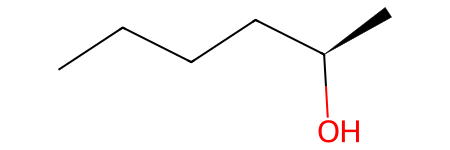

In [2]:
##(R)-2-hexanol
rhexanol=Chem.MolFromSmiles("C[C@@H](O)CCCC")
rhexanol

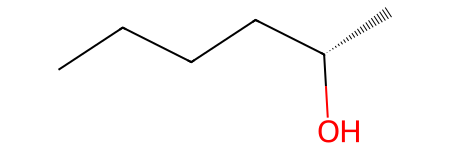

In [3]:
##(S)-2-hexanol
shexanol=Chem.MolFromSmiles("C[C@H](O)CCCC")
shexanol

In [4]:
from rdkit import Chem

from rdkit.Chem import Descriptors

In [5]:
#calculate the molecular weight of pentane
#pentane
pentane_smiles = "CCCCCC"
pentane_mol = Chem.MolFromSmiles(pentane_smiles)
# Calculate Molecular Weight
pentane_mw = Descriptors.MolWt(pentane_mol)
print(f"Molecular Weight of Pentane: {pentane_mw:.2f} g/mol")

Molecular Weight of Pentane: 86.18 g/mol


In [6]:
#Calculate the Molecular weight of the following, make use of the above code by modifying it
#hexanol
#pentanol
#Butane
#Aspirin
#Decane

# Calculate the Molecular Weight of the following compounds

from rdkit import Chem
from rdkit.Chem import Descriptors

# Define compounds and their SMILES
compounds = {
    "Hexanol": "CCCCCCO",
    "Pentanol": "CCCCCO",
    "Butane": "CCCC",
    "Aspirin": "CC(=O)OC1=CC=CC=C1C(=O)O",
    "Decane": "CCCCCCCCCC"
}

# Calculate and print molecular weights
for name, smiles in compounds.items():
    molecule = Chem.MolFromSmiles(smiles)
    molecular_weight = Descriptors.MolWt(molecule)
    print(f"Molecular Weight of {name}: {molecular_weight:.2f} g/mol")

Molecular Weight of Hexanol: 102.18 g/mol
Molecular Weight of Pentanol: 88.15 g/mol
Molecular Weight of Butane: 58.12 g/mol
Molecular Weight of Aspirin: 180.16 g/mol
Molecular Weight of Decane: 142.29 g/mol


In [7]:
# Install all required libraries
!pip install rdkit pubchempy requests -q
print("All libraries installed successfully!")

All libraries installed successfully!


In [8]:
# Import libraries for working with molecules
from rdkit import Chem
from rdkit.Chem import Draw, Descriptors, AllChem
from rdkit.Chem import SaltRemover

# Import library for PubChem
import pubchempy as pcp

# Other helpful libraries
import requests
import pandas as pd

print("All imports successful!")

All imports successful!


In [9]:
#Run the code to download the structure of Aspirin from Pubchem
import requests

name = "aspirin"

url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/{name}/SDF"

response = requests.get(url)

with open("aspirin.sdf", "w") as file:
    file.write(response.text)

print("Aspirin downloaded!")

Aspirin downloaded!


In [10]:
#Dowload the structure of the following compounds from PubChem
#hexanol
#pentanol
#Butane
#Mangiferin
#Decane


# Download the structure of the following compounds from PubChem

import requests
import os

compounds = {
    "hexanol": "hexanol",
    "pentanol": "pentanol",
    "butane": "butane",
    "mangiferin": "mangiferin",
    "decane": "decane"
}

# Create a folder to store the structures
folder = "PubChem_Structures"
os.makedirs(folder, exist_ok=True)

# Download SDF structures
for name, pubchem_name in compounds.items():

    url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/{pubchem_name}/SDF"

    response = requests.get(url)

    if response.status_code == 200:
        file_path = os.path.join(folder, f"{name}.sdf")

        with open(file_path, "w") as file:
            file.write(response.text)

        print(f"{name.capitalize()} downloaded successfully.")

    else:
        print(f"Could not download {name}.")

print("\nAll structures have been downloaded.")

Hexanol downloaded successfully.
Pentanol downloaded successfully.
Butane downloaded successfully.
Mangiferin downloaded successfully.
Decane downloaded successfully.

All structures have been downloaded.


In [11]:
#Run the following code to perform the following tasks
#20 compounds → PubChem → SDF → Canonical SMILES → RDKit → Lipinski screening → results table → Excel file


import requests
import pandas as pd
import os

from rdkit import Chem
from rdkit.Chem import Descriptors, Lipinski


# ==========================================
# 1. List of 20 compounds
# ==========================================

molecules = [

    "acetone",

    "ethanol",

    "methanol",

    "glucose",

    "fructose",

    "Decane",

    "Heptanol",

    "salicylic acid",

    "Mangiferin",

    "Rutin",

    "nicotinamide",

    "riboflavin",

    "Acetone",

    "aniline",

    "phenol",

    "toluene",

    "Decanol",

    "paroxetine",

    "testosterone",

    "progesterone"

]


# ==========================================
# 2. Create a folder for the SDF files
# ==========================================

folder = "molecules20"
os.makedirs(folder, exist_ok=True)


# ==========================================
# 3. Create an empty list for the results
# ==========================================

data = []


# ==========================================
# 4. Download and analyze each compound
# ==========================================

for number, name in enumerate(molecules, start=1):

    print(f"Processing {name}...")

    # PubChem URL for Canonical SMILES
    url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/{name}/property/CanonicalSMILES/JSON"

    response = requests.get(url)

    if response.status_code == 200:

        result = response.json()

        # Get Canonical SMILES
        smiles = result["PropertyTable"]["Properties"][0]["ConnectivitySMILES"]

        # Convert SMILES to an RDKit molecule
        molecule = Chem.MolFromSmiles(smiles)

        # ==========================================
        # 5. Download SDF file
        # ==========================================

        sdf_url = f"https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/{name}/SDF"

        sdf_response = requests.get(sdf_url)

        with open(f"{folder}/{name}.sdf", "w") as file:
            file.write(sdf_response.text)


        # ==========================================
        # 6. Calculate Lipinski properties
        # ==========================================

        molecular_weight = Descriptors.MolWt(molecule)

        logp = Descriptors.MolLogP(molecule)

        hbd = Lipinski.NumHDonors(molecule)

        hba = Lipinski.NumHAcceptors(molecule)


        # ==========================================
        # 7. Count Lipinski violations
        # ==========================================

        violations = 0

        if molecular_weight > 500:
            violations += 1

        if logp > 5:
            violations += 1

        if hbd > 5:
            violations += 1

        if hba > 10:
            violations += 1


        # ==========================================
        # 8. Determine Lipinski result
        # ==========================================

        if violations <= 1:
            rule = "Pass"
        else:
            rule = "Fail"


        # ==========================================
        # 9. Store results
        # ==========================================

        data.append([
            number,
            name,
            smiles,
            molecular_weight,
            logp,
            hbd,
            hba,
            violations,
            rule
        ])

    else:

        print(f"{name} could not be found on PubChem")


# ==========================================
# 10. Create results table
# ==========================================

table = pd.DataFrame(
    data,
    columns=[
        "S/N",
        "Compound",
        "Canonical SMILES",
        "Molecular Weight",
        "LogP",
        "HBD",
        "HBA",
        "Violations",
        "Lipinski Rule"
    ]
)


# ==========================================
# 11. Display the table
# ==========================================

display(table)



Processing acetone...
Processing ethanol...
Processing methanol...
Processing glucose...
Processing fructose...
Processing Decane...
Processing Heptanol...
Processing salicylic acid...
Processing Mangiferin...
Processing Rutin...
Processing nicotinamide...
Processing riboflavin...
Processing Acetone...
Processing aniline...
Processing phenol...
Processing toluene...
toluene could not be found on PubChem
Processing Decanol...
Processing paroxetine...
Processing testosterone...
Processing progesterone...


,S/N,Compound,Canonical SMILES,Molecular Weight,LogP,HBD,HBA,Violations,Lipinski Rule
0,1,acetone,CC(=O)C,58.080,0.59530,0,1,0,Pass
1,2,ethanol,CCO,46.069,-0.00140,1,1,0,Pass
2,3,methanol,CO,32.042,-0.39150,1,1,0,Pass
3,4,glucose,C(C1C(C(C(C(O1)O)O)O)O)O,180.156,-3.22140,5,6,0,Pass
4,5,fructose,C1C(C(C(C(O1)(CO)O)O)O)O,180.156,-3.21980,5,6,0,Pass
5,6,Decane,CCCCCCCCCC,142.286,4.14700,0,0,0,Pass
6,7,Heptanol,CCCCCCCO,116.204,1.94910,1,1,0,Pass
7,8,salicylic acid,C1=CC=C(C(=C1)C(=O)O)O,138.122,1.09040,2,2,0,Pass
8,9,Mangiferin,C1=C2C(=CC(=C1O)O)OC3=C(C2=O)C(=C(C(=C3)O)C4C(...,422.342,-0.71650,8,11,2,Fail
9,10,Rutin,CC1C(C(C(C(O1)OCC2C(C(C(C(O2)OC3=C(OC4=CC(=CC(...,610.521,-1.68710,10,16,3,Fail


In [12]:
table.to_csv("Lipinski_Results.csv", index=False)

from google.colab import files
files.download("Lipinski_Results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>